<a href="https://colab.research.google.com/github/SebastianoColombini/NN_DL_project/blob/main/v1.1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import section
from google.colab import drive
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import shutil
import os
import json
import shutil
import zipfile
from google.colab import drive
from torch.nn.modules import conv
import time
import matplotlib.pyplot as plt
import random

In [2]:
version = {
    "version_name": "1.1",
    "lr": 0.001,
    "epochs":150,
    "batch_size":16,
    "optimizer": "Adam",
    "patience": 15,
    "min_delta": 1e-4

}

### Download e Estrazione del Dataset SALICON

Ora scaricheremo il dataset SALICON. **Dovrai sostituire la `DOWNLOAD_URL` qui sotto con l'URL di download effettivo del tuo dataset SALICON.** Questo potrebbe essere un file `.zip` o `.tar.gz`.

Il codice scaricherà il file in una directory temporanea all'interno di `/DB`, lo estrarrà e poi tenterà di spostare le immagini e le mappe di salienza nelle cartelle `TRAIN_IMAGES_DIR` e `TRAIN_SALIENCY_MAPS_DIR` che abbiamo creato in precedenza.

## SALICON Dataset Loading

To use the SALICON dataset, we need to define a custom PyTorch `Dataset` class that handles loading the images and their corresponding saliency maps. This example assumes you have your dataset organized with separate directories for training images and saliency maps.

**Note:** You will need to adjust `root_dir_images`, `root_dir_saliency_maps`, and the image/saliency map loading logic to match your specific dataset structure and file formats.

In [3]:


drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/NN_DL_Proj"
VERSION_DIR = os.path.join(DRIVE_DIR, version["version_name"])
SNAPSHOTS_DIR = os.path.join(VERSION_DIR, "snapshots")
DB_DRIVE_DIR = os.path.join(DRIVE_DIR, 'DB')

os.makedirs(VERSION_DIR, exist_ok=True)
os.makedirs(SNAPSHOTS_DIR, exist_ok=True)

LOCAL_DB_DIR = "/content/extracted_db"

# LOCAR_DB_DIR is cleaned every run
if os.path.exists(LOCAL_DB_DIR):
    print(f"Cleaning existing directory: {LOCAL_DB_DIR}")
    shutil.rmtree(LOCAL_DB_DIR)
os.makedirs(LOCAL_DB_DIR, exist_ok=True)

def extract_dataset(zip_name):
    zip_path = os.path.join(DB_DRIVE_DIR, zip_name)
    if os.path.exists(zip_path):
        print(f"Estrazione di {zip_name} in corso...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(LOCAL_DB_DIR)
        print(f"Estrazione di {zip_name} completata.")
    else:
        print(f"ATTENZIONE: File {zip_name} non trovato in {DB_DRIVE_DIR}")

# Extract all the zips
for zip_file in [f for f in os.listdir(DB_DRIVE_DIR) if f.endswith('.zip')]:
    extract_dataset(zip_file)

TRAIN_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'train')
TRAIN_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'train')
VAL_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'val')
VAL_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'val')
TEST_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'test')
TEST_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'test')

#

version_file_path = os.path.join(VERSION_DIR, "version.json") #kind of useless
with open(version_file_path, 'w') as f:
    json.dump(version, f, indent=4)

# Directories:
print(f"- TRAIN_IMAGES_DIR: {TRAIN_IMAGES_DIR}")
print(f"- TRAIN_SALIENCY_MAPS_DIR: {TRAIN_SALIENCY_MAPS_DIR}")
print(f"- VAL_IMAGES_DIR: {VAL_IMAGES_DIR}")
print(f"- VAL_SALIENCY_MAPS_DIR: {VAL_SALIENCY_MAPS_DIR}")
print(f"- TEST_IMAGES_DIR: {TEST_IMAGES_DIR}")


Mounted at /content/drive
Estrazione di images.zip in corso...
Estrazione di images.zip completata.
Estrazione di maps.zip in corso...
Estrazione di maps.zip completata.
- TRAIN_IMAGES_DIR: /content/extracted_db/images/train
- TRAIN_SALIENCY_MAPS_DIR: /content/extracted_db/maps/train
- VAL_IMAGES_DIR: /content/extracted_db/images/val
- VAL_SALIENCY_MAPS_DIR: /content/extracted_db/maps/val
- TEST_IMAGES_DIR: /content/extracted_db/images/test


In [4]:
class SALICONDataset(Dataset):
    def __init__(self, image_root_dir, saliency_map_root_dir, transform=None):
        self.image_root_dir = image_root_dir
        self.saliency_map_root_dir = saliency_map_root_dir
        self.transform = transform

        VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

        # Filtriamo eventuali file "spuri" (.DS_Store, Thumbs.db, checkpoint di
        # Jupyter, ecc.) che altrimenti sfaserebbero l'accoppiamento per indice
        image_files = sorted(f for f in os.listdir(image_root_dir) if f.lower().endswith(VALID_EXTS))
        map_files = sorted(f for f in os.listdir(saliency_map_root_dir) if f.lower().endswith(VALID_EXTS))

        assert len(image_files) == len(map_files), \
            f"Mismatch: {len(image_files)} images vs {len(map_files)} maps"

        # Verifichiamo che i nomi (senza estensione) corrispondano 1:1, invece
        # di fidarci solo dell'ordine alfabetico. Se questo assert esplode
        # vuol dire che la convenzione dei nomi immagine/mappa non e' la
        # stessa e va adattata la logica di matching qui sotto.
        for img_f, map_f in zip(image_files, map_files):
            img_stem = os.path.splitext(img_f)[0]
            map_stem = os.path.splitext(map_f)[0]
            assert img_stem == map_stem, \
                f"Filename mismatch: image '{img_f}' vs map '{map_f}'"

        self.image_filenames = image_files
        self.saliency_map_filenames = map_files

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_name = os.path.join(self.image_root_dir, self.image_filenames[idx])
        saliency_name = os.path.join(self.saliency_map_root_dir, self.saliency_map_filenames[idx])

        image = Image.open(img_name).convert('RGB')
        saliency_map = Image.open(saliency_name).convert('L')

        if self.transform:
            image = self.transform(image)
            saliency_map = self.transform(saliency_map)

        return image, saliency_map

transforms_train = transforms.Compose([
    transforms.Resize((240,320)),
    transforms.ToTensor(),
])

# DATALOADER initialization
train_salicon_dataset = SALICONDataset(
    image_root_dir=TRAIN_IMAGES_DIR,
    saliency_map_root_dir=TRAIN_SALIENCY_MAPS_DIR,
    transform=transforms_train
)
val_salicon_dataset = SALICONDataset(
    image_root_dir=VAL_IMAGES_DIR,
    saliency_map_root_dir=VAL_SALIENCY_MAPS_DIR,
    transform=transforms_train
)

print(f"Number of samples in SALICON training dataset: {len(train_salicon_dataset)}")
print(f"Number of samples in SALICON validation dataset: {len(val_salicon_dataset)}")

Number of samples in SALICON training dataset: 10000
Number of samples in SALICON validation dataset: 5000


In [5]:
# THIS MUST BE REDONE PROBABLY
def normalize_map(s_map):
    """Normalizza la mappa affinché la somma di tutti i pixel sia pari a 1 (Distribuzione di probabilità)"""
    batch_size = s_map.size(0)
    s_map_flat = s_map.view(batch_size, -1)
    # Evitiamo la divisione per zero aggiungendo un piccolo epsilon
    s_map_sum = torch.sum(s_map_flat, dim=1, keepdim=True) + 1e-7
    s_map_norm = s_map_flat / s_map_sum
    return s_map_norm.view_as(s_map)

def kld_loss(pred, gt):
    """Kullback-Leibler Divergence Loss"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)
    eps = 1e-7
    # Formula KLD: Somma( GT * log(GT / (Pred + eps)) )
    loss = gt * torch.log(gt / (pred + eps) + eps)
    return torch.mean(torch.sum(loss.view(loss.size(0), -1), dim=1))

def cc_loss(pred, gt):
    """Pearson Correlation Coefficient Loss (espressa come 1 - CC per minimizzarla)"""
    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Calcolo delle medie
    pred_mean = torch.mean(pred_flat, dim=1, keepdim=True)
    gt_mean = torch.mean(gt_flat, dim=1, keepdim=True)

    # Centratura rispetto alla media
    pred_center = pred_flat - pred_mean
    gt_center = gt_flat - gt_mean

    # Formula di Pearson
    cc_num = torch.sum(pred_center * gt_center, dim=1)
    cc_den = torch.sqrt(torch.sum(pred_center ** 2, dim=1) * torch.sum(gt_center ** 2, dim=1) + 1e-7)

    cc = cc_num / cc_den
    return torch.mean(1 - cc) # Vogliamo massimizzare CC, quindi minimizziamo (1 - CC)

def sim_loss(pred, gt):
    """Histogram Similarity Loss (espressa come 1 - SIM)"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)

    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Prende il minimo pixel per pixel tra le due distribuzioni normalizzate
    sim = torch.sum(torch.min(pred_flat, gt_flat), dim=1)
    return torch.mean(1 - sim) # Vogliamo massimizzare la somiglianza

def single_loss(pred, gt, w_kld=1.0, w_cc=1.0, w_sim=1.0):
    """Combina le 3 perdite per un singolo ramo"""
    return w_kld * kld_loss(pred, gt) + w_cc * cc_loss(pred, gt) + w_sim * sim_loss(pred, gt)

def total_loss(final_map, s1, s2, s3, gt):
    """Calcola la loss totale applicando la Deep Supervision su tutti i rami"""
    l_final = single_loss(final_map, gt)
    l_s1 = single_loss(s1, gt)
    l_s2 = single_loss(s2, gt)
    l_s3 = single_loss(s3, gt)

    # Somma di tutte le loss (con pesi impostati a 1 come da impostazione standard)
    return l_final + l_s1 + l_s2 + l_s3

In [6]:
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.kernel_size = 3
    self.stride = 1
    self.padding = 1

    self.encoder_cnn1 = nn.Sequential(
        nn.Conv2d(3, 64, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Conv2d(64, 64, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn2 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.Conv2d(128, 128, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn3 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.Conv2d(256, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.Conv2d(256, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn4 = nn.Sequential(
        nn.Conv2d(256, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn5 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    x = self.encoder_cnn1(x)
    x = self.encoder_cnn2(x)
    x = self.encoder_cnn3(x)
    a = x.clone()
    x = self.encoder_cnn4(x)
    b = x.clone()
    x = self.encoder_cnn5(x)
    c = x.clone()

    return [a, b, c]

In [7]:
# DECODER 3
class Decoder3(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(256, 64, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(64),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [8]:
# DECODER 4
class Decoder4(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(512, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [9]:
# DECODER 5
class Decoder5(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(512, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [10]:
# FINAL LAYER
class FinalCov(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.ConvTranspose2d(3, 1, kernel_size=1, stride=1, padding=0),
        nn.Sigmoid()
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)


In [ ]:
# MAIN PHASE OF TRAINING

if torch.cuda.is_available():
        torch.cuda.empty_cache()

batch_size = version["batch_size"]
total_epochs = version["epochs"]
lr = version["lr"]

# --- Early stopping config ---
patience = version["patience"]        # epoche consecutive senza miglioramento della val loss prima di fermarsi
min_delta = version["min_delta"]      # miglioramento minimo (in val loss) per essere considerato "vero" miglioramento

encoder = Encoder()
decoder3 = Decoder3()
decoder4 = Decoder4()
decoder5 = Decoder5()
final = FinalCov()

loss_fn = nn.MSELoss()
optimizer = optim.Adam(
    list(encoder.parameters()) +
    list(decoder3.parameters()) +
    list(decoder4.parameters()) +
    list(decoder5.parameters()) +
    list(final.parameters())
    , lr
)

train_dataloader = DataLoader(train_salicon_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_dataloader = DataLoader(val_salicon_dataset, batch_size=batch_size, shuffle=False, num_workers=4)  # niente shuffle in val

# load on GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
encoder.to(device)
decoder3.to(device)
decoder4.to(device)
decoder5.to(device)
final.to(device)

# Snapshot logic (latest, per il resume)
encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_latest.pth")
decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_latest.pth")
decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_latest.pth")
decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_latest.pth")
final_path = os.path.join(SNAPSHOTS_DIR, f"final_latest.pth")
optimizer_path = os.path.join(SNAPSHOTS_DIR, f"optimizer_latest.pth")
progress_json_path = os.path.join(SNAPSHOTS_DIR, f"progress_latest.json")

# Snapshot logic (best, per l'early stopping)
best_encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_best.pth")
best_decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_best.pth")
best_decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_best.pth")
best_decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_best.pth")
best_final_path = os.path.join(SNAPSHOTS_DIR, f"final_best.pth")

train_losses_history = []
val_losses_history = []
best_val_loss = float('inf')
epochs_no_improve = 0
best_epoch = 0

# --- Resume training if snapshot exists ---
start_epoch = 0
if os.path.exists(progress_json_path):
    print("Found existing snapshot. Resuming training...")
    with open(progress_json_path, 'r') as f:
        epoch_data = json.load(f)
    start_epoch = epoch_data['epoch']
    train_losses_history = epoch_data['train_losses_history']
    val_losses_history = epoch_data['val_losses_history']

    # Nuovi campi per l'early stopping: uso .get per restare compatibili con
    # eventuali progress.json salvati prima di questa modifica
    best_val_loss = epoch_data.get('best_val_loss', min(val_losses_history) if val_losses_history else float('inf'))
    epochs_no_improve = epoch_data.get('epochs_no_improve', 0)
    best_epoch = epoch_data.get('best_epoch', 0)

    # Load model states (ultimo checkpoint, per continuare il training)
    encoder.load_state_dict(torch.load(encoder_path))
    decoder3.load_state_dict(torch.load(decoder3_path))
    decoder4.load_state_dict(torch.load(decoder4_path))
    decoder5.load_state_dict(torch.load(decoder5_path))
    final.load_state_dict(torch.load(final_path))

    # Load optimizer state
    optimizer.load_state_dict(torch.load(optimizer_path))

    print(f"Resuming from Epoch {start_epoch+1}. Best val loss so far: {best_val_loss:.4f} "
          f"(epoch {best_epoch}), no improvement for {epochs_no_improve} epoch(s).")


# Loop delle epoche
for epoch in range(start_epoch, total_epochs):
    # Training phase
    encoder.train()
    decoder3.train()
    decoder4.train()
    decoder5.train()
    final.train()

    total_train_loss_epoch = 0.0

    # TRAINING
    for i, (image_batch, saliency_map_batch) in enumerate(train_dataloader): # gather the batch

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        image_batch = image_batch.to(device)
        saliency_map_batch = saliency_map_batch.to(device)

        optimizer.zero_grad()

        latent_features = encoder(image_batch)
        saliency_3 = decoder3(latent_features[0])
        saliency_4 = decoder4(latent_features[1])
        saliency_5 = decoder5(latent_features[2])
        fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
        final_saliency_map = final(fused_input)

        # Calculate the loss using the loss_fn instance
        loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)
        loss.backward()
        optimizer.step()

        total_train_loss_epoch += loss.item()
        if (i + 1) % 100 == 0: # Print every 100 mini-batches
            print(f"Epoch [{epoch+1}/{total_epochs}], Step [{i+1}/{len(train_dataloader)}], Train Loss: {total_train_loss_epoch/(i+1):.4f}")

    avg_train_loss_epoch = total_train_loss_epoch / len(train_dataloader)
    train_losses_history.append(avg_train_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Train Loss: {avg_train_loss_epoch:.4f}")

    # VALIDATION
    encoder.eval()
    decoder3.eval()
    decoder4.eval()
    decoder5.eval()
    final.eval()

    total_val_loss_epoch = 0.0
    with torch.no_grad(): # No gradient calculations during the validation
        for i, (image_batch, saliency_map_batch) in enumerate(val_dataloader):
            image_batch = image_batch.to(device)
            saliency_map_batch = saliency_map_batch.to(device)

            latent_features = encoder(image_batch)
            saliency_3 = decoder3(latent_features[0])
            saliency_4 = decoder4(latent_features[1])
            saliency_5 = decoder5(latent_features[2])
            fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
            final_saliency_map = final(fused_input)

            # Calculate the loss using the loss_fn instance for validation
            loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)

            total_val_loss_epoch += loss.item()

    avg_val_loss_epoch = total_val_loss_epoch / len(val_dataloader)
    val_losses_history.append(avg_val_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Validation Loss: {avg_val_loss_epoch:.4f}")

    # --- Early stopping: confronto con il best e aggiornamento contatori ---
    if avg_val_loss_epoch < best_val_loss - min_delta:
        print(f"Val loss migliorata: {best_val_loss:.4f} -> {avg_val_loss_epoch:.4f}. Salvo il best checkpoint.")
        best_val_loss = avg_val_loss_epoch
        best_epoch = epoch + 1
        epochs_no_improve = 0

        torch.save(encoder.state_dict(), best_encoder_path)
        torch.save(decoder3.state_dict(), best_decoder3_path)
        torch.save(decoder4.state_dict(), best_decoder4_path)
        torch.save(decoder5.state_dict(), best_decoder5_path)
        torch.save(final.state_dict(), best_final_path)
    else:
        epochs_no_improve += 1
        print(f"Nessun miglioramento da {epochs_no_improve} epoca/e (best: {best_val_loss:.4f} @ epoch {best_epoch}).")

    # --- Save checkpoint (latest, per il resume) ---
    torch.save(encoder.state_dict(), encoder_path)
    torch.save(decoder3.state_dict(), decoder3_path)
    torch.save(decoder4.state_dict(), decoder4_path)
    torch.save(decoder5.state_dict(), decoder5_path)
    torch.save(final.state_dict(), final_path)
    torch.save(optimizer.state_dict(), optimizer_path)

    # Prepare data for JSON
    epoch_data = {
        "epoch": epoch + 1,
        "train_losses_history": train_losses_history,
        "val_losses_history": val_losses_history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_no_improve": epochs_no_improve,
        "model_snapshots": {
            "encoder": encoder_path,
            "decoder3": decoder3_path,
            "decoder4": decoder4_path,
            "decoder5": decoder5_path,
            "final": final_path,
            "optimizer": optimizer_path,
            "encoder_best": best_encoder_path,
            "decoder3_best": best_decoder3_path,
            "decoder4_best": best_decoder4_path,
            "decoder5_best": best_decoder5_path,
            "final_best": best_final_path
        }
    }

    # Save progress to JSON
    with open(progress_json_path, 'w') as f:
        json.dump(epoch_data, f, indent=4)

    print(f"Epoch {epoch+1} data and models saved to {SNAPSHOTS_DIR} (latest + best)")

    # --- Early stopping: interrompo il training se non migliora da troppo tempo ---
    if epochs_no_improve >= patience:
        print(f"\nEarly stopping attivato all'epoca {epoch+1}: nessun miglioramento della "
              f"val loss da {epochs_no_improve} epoche (best: {best_val_loss:.4f} all'epoca {best_epoch}).")
        break

Found existing snapshot. Resuming training...
Resuming from Epoch 26. Best val loss so far: 3.0735 (epoch 14), no improvement for 11 epoch(s).
Epoch [26/150], Step [100/625], Train Loss: 1.6787
Epoch [26/150], Step [200/625], Train Loss: 1.6847


In [12]:
# Con l'early stopping, il modello in memoria a fine training e' quello
# dell'ULTIMA epoca eseguita, non necessariamente il migliore (per costruzione
# ci alleniamo "patience" epoche oltre il best, per verificare che non stia
# migliorando piu'). Per la valutazione/inference ricarichiamo quindi i pesi
# del best checkpoint salvato durante il training.

encoder.load_state_dict(torch.load(best_encoder_path))
decoder3.load_state_dict(torch.load(best_decoder3_path))
decoder4.load_state_dict(torch.load(best_decoder4_path))
decoder5.load_state_dict(torch.load(best_decoder5_path))
final.load_state_dict(torch.load(best_final_path))

print(f"Caricato il best checkpoint (epoca {best_epoch}, val loss {best_val_loss:.4f}).")

Caricato il best checkpoint (epoca 14, val loss 3.0735).


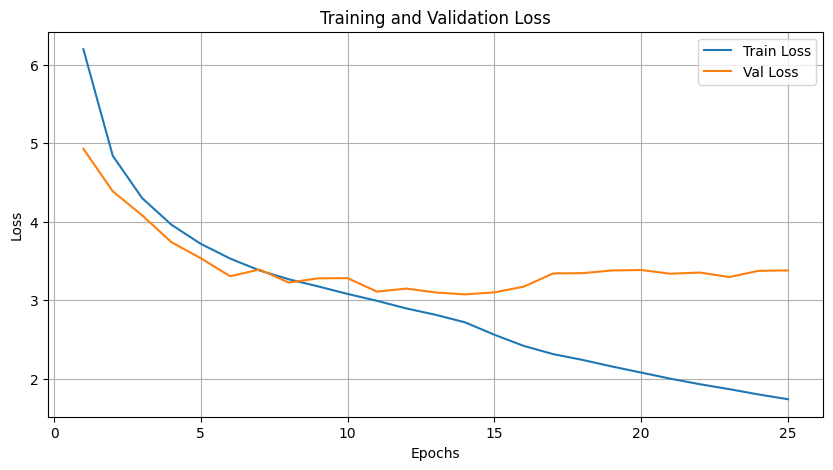

In [13]:
# Plotting Train/Validation errors
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_history) + 1), train_losses_history, label='Train Loss')
plt.plot(range(1, len(val_losses_history) + 1), val_losses_history, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

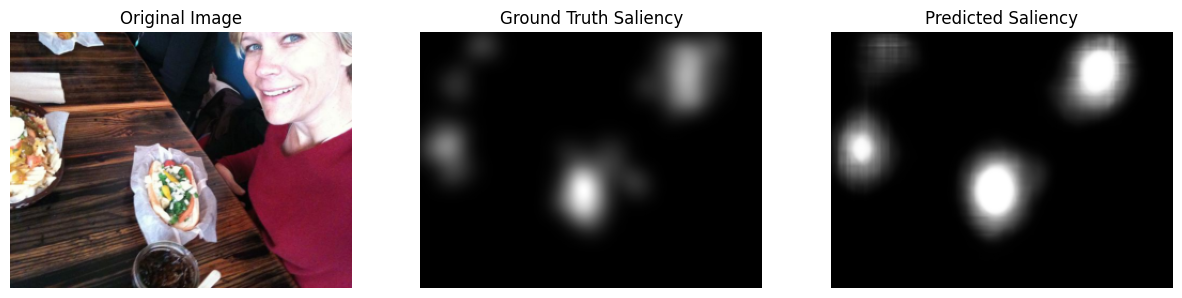

In [14]:
with torch.no_grad():
    img_idx = 3

    # first element of the last image batch
    sample_img = image_batch[img_idx].cpu()
    sample_gt = saliency_map_batch[img_idx].cpu()
    sample_pred = final_saliency_map[img_idx].cpu()

    # Unnormalize image for visualization (assuming ToTensor() was used)
    img_display = sample_img.permute(1, 2, 0).numpy()
    gt_display = sample_gt.squeeze().numpy()
    pred_display = sample_pred.squeeze().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(gt_display, cmap='gray')
    axes[1].set_title('Ground Truth Saliency')
    axes[1].axis('off')

    axes[2].imshow(pred_display, cmap='gray')
    axes[2].set_title('Predicted Saliency')
    axes[2].axis('off')

    plt.show()

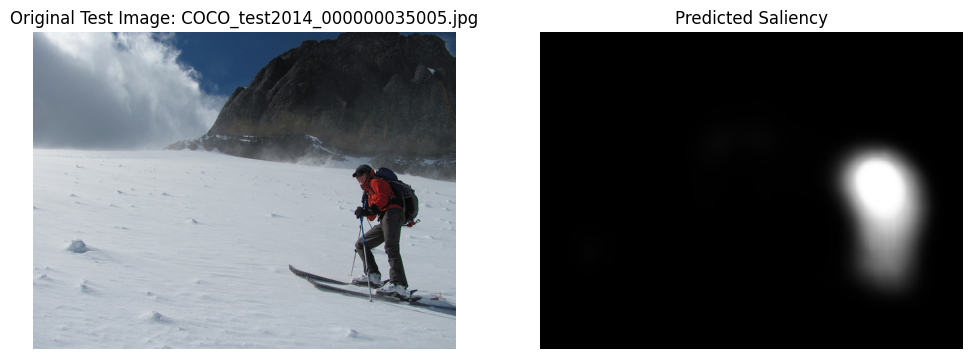

In [17]:


# Put models in evaluation mode
encoder.eval()
decoder3.eval()
decoder4.eval()
decoder5.eval()
final.eval()

# List all images in the test directory
test_images = [f for f in os.listdir(TEST_IMAGES_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if not test_images:
    print(f"No images found in {TEST_IMAGES_DIR}")
else:
    # Choose a random image
    random_img_name = random.choice(test_images)
    img_path = os.path.join(TEST_IMAGES_DIR, random_img_name)

    # Load and transform
    raw_image = Image.open(img_path).convert('RGB')
    input_tensor = transforms_train(raw_image).unsqueeze(0).to(device)

    with torch.no_grad():
        # Forward pass
        latent = encoder(input_tensor)
        s3 = decoder3(latent[0])
        s4 = decoder4(latent[1])
        s5 = decoder5(latent[2])
        fused = torch.cat((s3, s4, s5), dim=1)
        prediction = final(fused)

    # Prepare for display
    pred_np = prediction.squeeze().cpu().numpy()

    # Plotting
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(raw_image)
    plt.title(f"Original Test Image: {random_img_name}")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(pred_np, cmap='gray')
    plt.title("Predicted Saliency")
    plt.axis('off')

    plt.show()